# Reto Planta Física
# Parte 1: Investigación

| | |
|---|---|
| **Grupo** | 201 |
| **Equipo** | 11 |

| Matrícula | Integrante |
|---|---|
| A01668975 | Jesús Emilio Arroyo Camarena |
| A01660285 | Diana Paulina Cano García |
| A00841256 | Fátima Sofía Sacoto Idrovo |

### Responsabilidades y rotaciones

| Rol | Integrante | Qué hizo | Rotación |
|---|---|---|---|
| Programación | Jesús Emilio Arroyo Camarena | Se encargó del código | NO |
| Revisión | Fátima Sofía Sacoto Idrovo  | Revisión del código y redacción | NO |
| Verificación | Diana Paulina Cano García| Verificación de resultados y presentación | NO |

### Cambios

Conservamos todas las secciones de la base común (1 a 11 y Procedencia y entorno). Las celdas que agregamos para Investigación llevan el encabezado Investigación y están junto al contenido que complementan, organizadas en cuatro apartados:

1. Formulación y supuestos.
2. Cálculo manual.
3. Comparación con `evaluate`.
4. Interpretación y correcciones.

Esta libreta integra en un solo archivo la base común (`reto_planta_fisica_solucion_minima.ipynb`) y la evidencia de Investigación.

# Planta Física


## 1. Definir el problema

Asignamos una fracción de agua tratada a cada edificio para reducir el agua potable. Usamos demandas agregadas reales de marzo de 2025: Aulas 1 = 847, Biblioteca = 462, Cedetec = 284.21 y Aulas 2 = 683 m³. Conservamos ese orden. Los cuatro registros no tienen banderas de imputación, cero ni anomalía.

Adoptamos 1,410 m³ como capacidad didáctica, tomada de la calibración docente existente; no es una capacidad confirmada por el socio. También tratamos los límites por edificio como supuestos didácticos.

Codificamos $k=(k_1,k_2,k_3,k_4)$ con enteros: $k_1,k_2,k_4\in\{0,\ldots,8\}$ y $k_3\in\{0,\ldots,6\}$. Interpretamos $x_i=k_i/10$. Por ejemplo, el gen 6 representa 60% de reúso. Hay $9\times9\times7\times9=5103$ combinaciones; exploramos algunas mediante el algoritmo genético.

In [1]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])
LIMITS = np.array([8, 8, 6, 8])
CAPACITY = 1410.0

## Apartado 1: formulación y supuestos

### 1.1 La decisión física y los genes

Para cada uno de los cuatro edificios decidimos qué porcentaje de su demanda mensual cubrimos con agua tratada (reúso), mediante cuatro niveles enteros $k=(k_1,k_2,k_3,k_4)$. El resto de la demanda lo cubre agua potable. Permanecen fijos: las demandas $D_i$, la capacidad $C$ y los dominios de cada gen.   

Conservamos siempre el mismo orden en las tablas, el cromosoma y el código:

| Posición | Gen | Edificio | Dominio entero de $k_i$ | Fracción $x_i=k_i/10$ | Reúso máximo | Valores posibles |
|---|---|---|---|---|---|---|
| 1 | $k_1$ | Aulas 1 | 0 a 8 | 0.0 a 0.8 | 80 % | 9 |
| 2 | $k_2$ | Biblioteca | 0 a 8 | 0.0 a 0.8 | 80 % | 9 |
| 3 | $k_3$ | Cedetec | 0 a 6 | 0.0 a 0.6 | 60 % | 7 |
| 4 | $k_4$ | Aulas 2 | 0 a 8 | 0.0 a 0.8 | 80 % | 9 |

Distinguimos tres magnitudes:

- Nivel entero $k_i$ (el gen): número entero sin unidades. Cada nivel equivale a diez puntos porcentuales.
- Fracción $x_i=k_i/10$: número sin unidades entre 0 y 1; el porcentaje de reúso es $100x_i$.
- Volumen $T_i=D_i\,k_i/10$: cantidad de agua tratada en m³.

Ejemplo: $k_3=6$ en Cedetec representa $x_3=0.60$, es decir 60 % de su demanda, y $T_3=284.21\times0.6=170.526$ m³. Nunca usamos $k_i$ directamente como fracción. En Cedetec el nivel 8 no es válido porque su máximo didáctico es 60 %.

### 1.2 Datos fijos

Demandas agregadas de marzo de 2025, en m³ (consumos observados):

| Edificio | Mes | Demanda $D_i$ (m³) |
|---|---|---|
| Aulas 1 | marzo de 2025 | 847.00 |
| Biblioteca | marzo de 2025 | 462.00 |
| Cedetec | marzo de 2025 | 284.21 |
| Aulas 2 | marzo de 2025 | 683.00 |
| Total $Q$ | marzo de 2025 | 2276.21 |

Las demandas provienen del archivo `consumo_agua_2023_2026.csv` del kit del repositorio técnico MA2015-Planta-Fisica (cuyo registro de origen es `consumo-agua.xlsx`, con fecha de corte 2026-08-21), filtrado a marzo de 2025 e incorporado en la base de esta libreta; la metadata de la libreta conserva los cuatro registros y los hashes de las fuentes completas. Cada $D_i$ es la suma del agua tratada y la potable registradas en el mes (por ejemplo, Aulas 1: 647.0 + 200.0 = 847.0 m³). Los cuatro registros no tienen banderas de imputación, cero ni anomalía.

### 1.3 Objetivo, fórmulas y restricción

Para un cromosoma $k$:

$$T_i=\frac{D_i\,k_i}{10},\qquad P_i=D_i-T_i,\qquad T=\sum_{i=1}^{4}T_i,\qquad P=Q-T,\qquad E=\max(0,\,T-C)$$

$$F(k)=\begin{cases}\dfrac{P}{Q} & \text{si } T\le C\ \ (\text{factible})\\[2mm] 1+\dfrac{E}{C} & \text{si } T>C\ \ (\text{infactible})\end{cases}$$

$T_i$ y $P_i$ son los volúmenes tratado y potable del edificio $i$; $T$ y $P$ son los totales; $E$ es el exceso de capacidad. Todos están en m³; $k_i$, $x_i$ y $F$ no tienen unidades.

Minimizamos el agua potable $P$ sujeto a los dominios y a $T\le C$. Cada m³ de agua tratada que usamos sustituye un m³ de agua potable, así que reducir $P$ equivale a aprovechar más el reúso, pero sólo hasta donde la planta alcanza.

$F$ es una aptitud donde menor es mejor. Para un plan factible, $F=P/Q$ es la fracción de la demanda que sigue cubierta con agua potable, y por eso $F\le1$. Un plan que rebasa la capacidad recibe $F=1+E/C>1$, de modo que cualquier plan factible es mejor que cualquier plan infactible. En código, la factibilidad se comprueba con tolerancia numérica: un candidato cumple si $E\le10^{-8}$ m³. Un cromosoma fuera de dominio o con valores no enteros se rechaza (la función lanza un error); un cromosoma válido que rebasa la capacidad se evalúa por la rama infactible.

### 1.4 Datos observados frente a supuestos didácticos

| Elemento | Valor | Naturaleza |
|---|---|---|
| Demandas $D_i$ de marzo de 2025 | 847.00, 462.00, 284.21, 683.00 m³ | Consumos observados |
| Capacidad $C$ | 1410 m³ | Supuesto didáctico, tomado de la calibración docente existente; no es una capacidad confirmada por el socio |
| Reúso máximo por edificio | 80 %, 80 %, 60 %, 80 % | Supuestos didácticos |
| Tolerancia de factibilidad | $10^{-8}$ m³ | Decisión técnica de cálculo numérico |

### 1.5 Alcance

El modelo describe un ejercicio mensual (marzo de 2025) con cuatro edificios. No representa un año completo ni otros meses, y sus resultados no constituyen una recomendación hidráulica o sanitaria validada.

In [2]:
# Verificación de los datos y dominios que acabamos de documentar
assert BUILDINGS == ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
Q = float(np.sum(DEMAND))
print(f"Demanda total Q = {Q:.2f} m³")
print(f"Capacidad didáctica C = {CAPACITY:.0f} m³")
print(f"Combinaciones posibles = {int(np.prod(LIMITS + 1))}")
print()
print(f"{'gen':<5}{'edificio':<12}{'D_i (m³)':>10}{'dominio':>10}{'x_i máx':>10}{'reúso máx':>11}")
for i, (name, d, lim) in enumerate(zip(BUILDINGS, DEMAND, LIMITS), start=1):
    print(f"k{i:<4}{name:<12}{d:>10.2f}{'0 a ' + str(lim):>10}{lim / 10:>10.1f}{lim * 10:>10d} %")
assert np.isclose(Q, 2276.21)

Demanda total Q = 2276.21 m³
Capacidad didáctica C = 1410 m³
Combinaciones posibles = 5103

gen  edificio      D_i (m³)   dominio   x_i máx  reúso máx
k1   AULAS 1         847.00     0 a 8       0.8        80 %
k2   BIBLIOTECA      462.00     0 a 8       0.8        80 %
k3   CEDETEC         284.21     0 a 6       0.6        60 %
k4   AULAS 2         683.00     0 a 8       0.8        80 %


## 2. Calculamos agua y aptitud

Definimos agua tratada $T=\sum_iD_i k_i/10$, agua potable $P=\sum_iD_i-T$ y exceso $E=\max(0,T-C)$. Minimizamos $P$ sujeto al dominio y $T\le C$.

Ordenamos candidatos con $F=P/\sum D_i$ si son factibles y $F=1+E/C$ si exceden la capacidad. Menor aptitud es mejor. Una solución factible tiene $F\le1$; una infactible tiene $F>1$. Usamos tolerancia numérica de $10^{-8}$ m³.

Antes de ejecutar, calcula a mano $k=(6,6,6,6)$: $T=0.6(2276.21)=1365.726$, $P=910.484$, $E=0$, $F=0.4$. Explica por qué cumple la capacidad y qué unidad tiene cada resultado.

In [3]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

## Apartado 2: cálculo manual

Elegimos el cromosoma $k=(6,6,6,6)$, que usa la guía. Es válido porque cada gen es entero y está dentro de su dominio: $6\in\{0,\ldots,8\}$ en Aulas 1, Biblioteca y Aulas 2, y $6\in\{0,\ldots,6\}$ en Cedetec (su máximo). Todas las fracciones son $x_i=6/10=0.60$.

Hacemos el cálculo antes de consultar la salida de `evaluate`.

| Edificio | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i$ (m³) | $P_i$ (m³) |
|---|---|---|---|---|---|
| Aulas 1 | 847.00 | 6 | 0.60 | 508.200 | 338.800 |
| Biblioteca | 462.00 | 6 | 0.60 | 277.200 | 184.800 |
| Cedetec | 284.21 | 6 | 0.60 | 170.526 | 113.684 |
| Aulas 2 | 683.00 | 6 | 0.60 | 409.800 | 273.200 |

Sustituciones por edificio

- Aulas 1: $T_1=847.00\times\frac{6}{10}=847.00\times0.6=508.200$ m³; $P_1=847.00-508.200=338.800$ m³.
- Biblioteca: $T_2=462.00\times0.6=277.200$ m³; $P_2=462.00-277.200=184.800$ m³.
- Cedetec: $T_3=284.21\times0.6=170.526$ m³; $P_3=284.21-170.526=113.684$ m³.
- Aulas 2: $T_4=683.00\times0.6=409.800$ m³; $P_4=683.00-409.800=273.200$ m³.

Totales

- $T=508.200+277.200+170.526+409.800=1365.726$ m³.
- $P=Q-T=2276.21-1365.726=910.484$ m³. Como comprobación, $338.800+184.800+113.684+273.200=910.484$ m³.

Exceso y factibilidad

- $E=\max(0,\,1365.726-1410)=\max(0,\,-44.274)=0$ m³.
- Como $T=1365.726\le C=1410$, el plan es factible: queda un margen de 44.274 m³ de capacidad.

Aptitud (rama factible, porque $T\le C$):

$$F=\frac{P}{Q}=\frac{910.484}{2276.21}=0.4$$

El resultado es exactamente 0.4 porque con reúso uniforme de 60 % el potable es el 40 % de la demanda total.

**Comprobaciones de consistencia**

- $T_i+P_i=D_i$ en cada edificio: $508.200+338.800=847.00$; $277.200+184.800=462.00$; $170.526+113.684=284.21$; $409.800+273.200=683.00$.
- $T+P=1365.726+910.484=2276.21=Q$.

Unidades: $T_i$, $P_i$, $T$, $P$ y $E$ en m³; $k_i$, $x_i$ y $F$ sin unidades.

In [4]:
# Verificación aritmética del cálculo manual con decimales exactos
from decimal import Decimal as Dec

D_exact = [Dec("847.00"), Dec("462.00"), Dec("284.21"), Dec("683.00")]
k_manual = [6, 6, 6, 6]
C_exact = Dec("1410")
Q_exact = sum(D_exact)

T_i = [d * k / 10 for d, k in zip(D_exact, k_manual)]
P_i = [d - t for d, t in zip(D_exact, T_i)]
T_exact, P_exact = sum(T_i), Q_exact - sum(T_i)
E_exact = max(Dec(0), T_exact - C_exact)
F_exact = P_exact / Q_exact if T_exact <= C_exact else 1 + E_exact / C_exact

print(f"{'edificio':<12}{'D_i':>10}{'k_i':>5}{'T_i':>10}{'P_i':>10}")
for name, d, k, t, p in zip(BUILDINGS, D_exact, k_manual, T_i, P_i):
    assert t + p == d  # T_i + P_i = D_i
    print(f"{name:<12}{d:>10}{k:>5}{t:>10}{p:>10}")
assert T_exact + P_exact == Q_exact  # T + P = Q
print(f"\nT = {T_exact} m³   P = {P_exact} m³   Q = {Q_exact} m³")
print(f"E = {E_exact} m³   factible = {E_exact <= Dec('1e-8')}   F = {F_exact}")

edificio           D_i  k_i       T_i       P_i
AULAS 1         847.00    6    508.20    338.80
BIBLIOTECA      462.00    6    277.20    184.80
CEDETEC         284.21    6   170.526   113.684
AULAS 2         683.00    6    409.80    273.20

T = 1365.726 m³   P = 910.484 m³   Q = 2276.21 m³
E = 0 m³   factible = True   F = 0.4


## Apartado 3: comparación con `evaluate`

Ejecutamos `evaluate` con los mismos datos y los mismos genes del cálculo manual, $k=(6,6,6,6)$.

In [5]:
genes = np.array([6, 6, 6, 6], dtype=int)
resultado = evaluate(genes)
resultado

{'treated': 1365.7259999999999,
 'potable': 910.4840000000002,
 'excess': 0.0,
 'feasible': True,
 'fitness': 0.4000000000000001}

In [6]:
# Valores obtenidos a mano en el Apartado 2
manual = dict(treated=1365.726, potable=910.484, excess=0.0, feasible=True, fitness=0.4)

print(f"{'clave':<10}{'manual':>14}{'evaluate':>22}{'diferencia':>14}")
for key in ("treated", "potable", "excess", "fitness"):
    diff = resultado[key] - manual[key]
    print(f"{key:<10}{manual[key]:>14.3f}{resultado[key]:>22.15f}{diff:>14.2e}")
    assert abs(diff) < 1e-9, key
print(f"{'feasible':<10}{str(manual['feasible']):>14}{str(resultado['feasible']):>22}"
      f"{'coinciden' if manual['feasible'] == resultado['feasible'] else 'DIFIEREN':>14}")
assert manual["feasible"] == resultado["feasible"]

clave             manual              evaluate    diferencia
treated         1365.726  1365.725999999999885     -2.27e-13
potable          910.484   910.484000000000151      1.14e-13
excess             0.000     0.000000000000000      0.00e+00
fitness            0.400     0.400000000000000      5.55e-17
feasible            True                  True     coinciden


**Tabla de comparación**

| Cantidad | Valor manual | Valor de `evaluate` | Diferencia (evaluate − manual) |
|---|---|---|---|
| $T$ (`treated`, m³) | 1365.726 | 1365.7259999999999 | −2.27 × 10⁻¹³ m³ |
| $P$ (`potable`, m³) | 910.484 | 910.4840000000002 | 1.14 × 10⁻¹³ m³ |
| $E$ (`excess`, m³) | 0 | 0.0 | 0 |
| $F$ (`fitness`, sin unidades) | 0.4 | 0.4000000000000001 | 5.55 × 10⁻¹⁷ |
| Factibilidad (`feasible`) | factible ($T\le C$) | `True` | coinciden |

Conservamos la precisión completa durante todos los cálculos y sólo redondeamos al presentar: volúmenes con tres decimales (m³) y la aptitud con la precisión indicada en la tabla. Como las demandas tienen a lo más dos decimales y se multiplican por $0.6$, los valores manuales de $T$ y $P$ son exactos con tres decimales y no hubo redondeo en ellos.

Los cinco resultados coinciden con el cálculo manual: `treated` $=T$, `potable` $=P$, `excess` $=E=0$, `feasible` es verdadero porque $E\le10^{-8}$ m³ y `fitness` $=F=P/Q=0.4$. La función aplica las mismas fórmulas que usamos a mano: $T=\sum D_ik_i/10$, $P=Q-T$, $E=\max(0,T-C)$ y la rama $P/Q$ al ser factible.

Las diferencias numéricas de la tabla son del orden de $10^{-13}$ m³ (y $10^{-16}$ en $F$). No corresponden a un error de fórmula, de unidades, de orden de edificios ni de conversión: vienen de la representación en punto flotante de doble precisión (por ejemplo, 0.6 y 284.21 no son exactos en binario). Son decenas de miles de veces menores que la tolerancia de $10^{-8}$ m³ y unas $10^{14}$ veces menores que el margen de 44.274 m³ de este plan, así que no afectan la factibilidad ni la rama de aptitud.

Comprobando tres candidatos, cero reúso, 60% uniforme y máximos del dominio. Distingue cumplir el dominio de cumplir la capacidad. Las claves `treated`, `potable`, `excess`, `feasible` y `fitness` corresponden a $T$, $P$, $E$, factibilidad y $F$.

In [7]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))
assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


El plan máximo usa 1764.126 m³ tratados, excede la capacidad en 354.126 m³ y obtiene $F>1$. Aunque reduce más el agua potable, lo descartamos por infactible. Conserva el cálculo manual y la explicación de tu equipo como evidencia de Investigación.

## Apartado 4: interpretación y correcciones

### Cromosoma máximo $k=(8,8,6,8)$

Es el cromosoma que toma el valor máximo permitido en cada edificio.

Sustituciones

- $T_1=847.00\times0.8=677.600$ m³
- $T_2=462.00\times0.8=369.600$ m³
- $T_3=284.21\times0.6=170.526$ m³
- $T_4=683.00\times0.8=546.400$ m³
- $T=677.600+369.600+170.526+546.400=1764.126$ m³
- $P=Q-T=2276.21-1764.126=512.084$ m³
- $E=\max(0,\,1764.126-1410)=354.126$ m³ (equivale a $354.126/1410\approx25.1\,\%$ de la capacidad)
- Como $T>C$, el plan es infactible y usamos la rama penalizada: $F=1+\dfrac{E}{C}=1+\dfrac{354.126}{1410}\approx1.2512$

Por qué sus genes son válidos. Los cuatro son enteros y respetan su dominio: $8\le8$ en Aulas 1, Biblioteca y Aulas 2, y $6\le6$ en Cedetec (el máximo de Cedetec es 6, no 8). Ninguno es negativo ni fraccionario. Por tanto `evaluate` lo acepta sin error.

Por qué, aun así, rebasa la capacidad. Los dominios acotan cada gen por separado (cuánto reúso máximo admite cada edificio), mientras que la capacidad limita la suma de los volúmenes tratados de los cuatro edificios. Cada máximo es individualmente razonable, pero juntos suman 1764.126 m³, que es mayor que los 1410 m³ disponibles. Cumplir el dominio no garantiza cumplir la capacidad; son dos condiciones distintas.

Rama de aptitud. Le corresponde $F=1+E/C$ porque $T>C$. Si le aplicáramos $P/Q$, obtendríamos $512.084/2276.21\approx0.225$, un valor mucho mejor que el de los planes factibles (por ejemplo, $0.4$ para $(6,6,6,6)$), y premiaríamos justo un plan que no se puede ejecutar. La rama penalizada lo coloca por encima de 1, peor que cualquier plan factible, y además crece con el exceso, de modo que entre dos planes infactibles el que rebasa menos tiene mejor aptitud.

Significado físico del exceso.$E=354.126$ m³ es el volumen mensual de agua tratada que este plan pediría **por encima de la capacidad didáctica** de 1410 m³. Como esa capacidad es un supuesto del ejercicio y no una capacidad confirmada de la planta, la lectura es válida dentro del modelo mensual de marzo de 2025.

In [8]:
# Cromosoma máximo (8, 8, 6, 8): cálculo por edificio y contraste con evaluate
genes_max = np.array([8, 8, 6, 8], dtype=int)
assert np.all(genes_max == LIMITS)

T_i_max = DEMAND * genes_max / 10
for name, d, k, t in zip(BUILDINGS, DEMAND, genes_max, T_i_max):
    print(f"{name:<12} D={d:>8.2f} m³  k={k}  T_i={t:>9.3f} m³")

res_max = evaluate(genes_max)
print()
print(f"T = {res_max['treated']:.3f} m³  (capacidad C = {CAPACITY:.0f} m³)")
print(f"P = {res_max['potable']:.3f} m³")
print(f"E = {res_max['excess']:.3f} m³  = {100 * res_max['excess'] / CAPACITY:.1f} % de C")
print(f"factible = {res_max['feasible']}")
print(f"F (rama penalizada 1 + E/C) = {res_max['fitness']:.6f}")
print(f"Si se aplicara P/Q por error: {res_max['potable'] / np.sum(DEMAND):.4f}")

assert np.isclose(res_max["treated"], 1764.126)
assert np.isclose(res_max["excess"], 354.126)
assert not res_max["feasible"]
assert np.isclose(res_max["fitness"], 1 + 354.126 / 1410)

AULAS 1      D=  847.00 m³  k=8  T_i=  677.600 m³
BIBLIOTECA   D=  462.00 m³  k=8  T_i=  369.600 m³
CEDETEC      D=  284.21 m³  k=6  T_i=  170.526 m³
AULAS 2      D=  683.00 m³  k=8  T_i=  546.400 m³

T = 1764.126 m³  (capacidad C = 1410 m³)
P = 512.084 m³
E = 354.126 m³  = 25.1 % de C
factible = False
F (rama penalizada 1 + E/C) = 1.251153
Si se aplicara P/Q por error: 0.2250


### Correcciones y notas

- No encontramos diferencias de fondo entre el cálculo manual frente a `evaluate` (fórmulas, unidades, orden de edificios, conversión $x_i=k_i/10$ ni aplicación de la restricción). Las únicas diferencias son de punto flotante, del orden de $10^{-13}$ m³, y no requieren corrección.
- El cálculo manual del cromosoma máximo coincide con `evaluate`: el plan respeta los dominios, rebasa la capacidad y recibe la rama penalizada.
- No modificamos el código de la base; las celdas agregadas sólo leen sus datos y llaman a `evaluate`.
- Estos apartados, junto con el modelo y el evaluador de la base, son el punto de partida de Desarrollo: usaremos el mismo modelo para interpretar los candidatos que produzca el algoritmo genético.

In [9]:
##########################################FIN ETAPA DE INVESTIGACIÓN#######################################################

## 3. Generar una población

Una población es una lista de candidatos. Muestreamos cada gen dentro de su dominio, incluidos los extremos. El muestreo no garantiza capacidad: la función de aptitud ordena también los candidatos infactibles. Fijamos la semilla para reproducir esta demostración.

In [10]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. Seleccionar padres mediante torneo

Tomamos dos candidatos distintos al azar y elegimos el de menor $F$. Repetimos para elegir otro padre; un mismo individuo puede ganar varios torneos. La selección favorece aptitudes bajas sin ordenar siempre toda la población. Devolvemos una copia para proteger el original.

In [11]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. Combinar información con cruza de un punto

Elegimos un corte entre posiciones y tomamos el inicio del primer padre y el final del segundo. Conservamos la posición de cada edificio. Con padres $(6,6,6,6)$ y $(8,2,4,3)$ y corte 2 obtenemos $(6,6,4,3)$. La cruza preserva dominios, pero puede producir exceso de capacidad.

In [12]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. Introducir variación con mutación

Aplicamos la probabilidad a cada gen, no al cromosoma completo. Cada gen elegido sube o baja un nivel válido. En cero sólo subimos; en el máximo sólo bajamos. Con $p=0.25$ y cuatro genes, esperamos un gen seleccionado por hijo en promedio, no exactamente uno. La mutación puede mejorar o empeorar la aptitud.

In [13]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. Reemplazar la población y conservar una élite

Copiamos el mejor individuo sin modificarlo y llenamos las posiciones restantes con hijos. Mantenemos el tamaño de la población. El elitismo evita perder el mejor valor de aptitud; no demuestra que ya encontramos el óptimo. Con una copia independiente, mutar un hijo no modifica al padre ni a la élite.

In [14]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. Cerrar el ciclo

Inicializamos, evaluamos y repetimos selección, cruza, mutación y reemplazo durante un número fijo de generaciones. Registramos el mejor $F$ inicial y después de cada generación. Con 20 generaciones obtenemos 21 valores, incluido el estado inicial. No esperamos una mejora en cada paso.

In [15]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## DESARROLLO - ENTREGABLE 2: VARIANTE CON UN OPERADOR MODIFICADO

En este bloque conservamos la base y agregamos una variante que modifica un solo operador. Comparamos las versiones con semilla 42 y las mismas condiciones, y relacionamos el resultado con la asignación del agua. El modelo, los datos, el evaluador y el cálculo manual son los de Investigación y no cambian.

Aclaración sobre las secciones 9 a 11: Esas secciones de la base comparan pm = 0.25 con pm = 0.50 sobre el mismo código y pertenecen a la Etapa Final. No son la variante del Desarrollo: aquí ambas versiones usan pm = 0.25 y la diferencia está en un operador.

## D1. La base y la función de cada paso.

| Paso | Función de la base | Que hace |
|---|---|---|
| Población inicial | `random_individual` | Muestrea cada gen entero dentro de su dominio, incluidos los extremos. |
| Aptitud | `evaluate` | Calcula $T$, $P$, $E$, factibilidad y $F$ (menor es mejor) y rechaza genes inválidos. |
| Selección | `tournament` | Torneo de dos candidatos distintos; gana el de menor $F$; devuelve una copia. |
| Cruza | `crossover` | Cruza de un punto: inicio del primer padre y final del segundo. |
| Mutación | `mutate` | Con probabilidad pm por gen, sube o baja un nivel válido. |
| Reemplazo y élite | `next_generation` | Copia al mejor individuo y llena el resto con hijos; la población mantiene su tamaño. |
| Ciclo | `run_ga` | Repite las generaciones y registra la mejor $F$ inicial y de cada generación. |

Ese código está en las secciones 3 a 8, no lo modificamos y se ejecuta por separado con `run_ga`.

### D2. Limitación que identificamos en un operador.

La cruza de un punto de la base (`crossover`) combina a los padres de una forma muy restringida:

- Con cuatro genes sólo existen tres cortes posibles (entre $k_1|k_2$, $k_2|k_3$ y $k_3|k_4$). Con dos padres $A$ (primero) y $B$ (segundo) produce como máximo 3 hijos distintos.
- Siempre hereda $k_1$ del primer padre y $k_4$ del segundo, y nunca forma combinaciones salteadas como $(A,B,B,A)$ o $(A,B,A,B)$.
- En la ejecución base de este bloque (más abajo) la mejor aptitud no cambia entre las generaciones 0 y 16 y sólo mejora en la 17: la recombinación tarda en entregar un candidato mejor.

La siguiente celda comprueba los dos primeros puntos con código.

## D3. Cambio propuesto e hipótesis.

Cambio (un solo operador: la cruza). Sustituimos la cruza de un punto por una cruza uniforme: para cada gen lanzamos una moneda justa y tomamos su valor del primer o del segundo padre. Selección, mutación, reemplazo, élite, datos, evaluador y parámetros quedan iguales a la base.

Mecanismo: Al decidir cada gen por separado, dos padres distintos pueden dar hasta $2^4=16$ combinaciones (14 mezcladas y 2 copias de un padre) y desaparece el sesgo de posición. El agua tratada es una suma de aportes por edificio: cada nivel de $k_i$ agrega $0.1D_i$ a $T$ (84.7, 46.2, 28.421 y 68.3 m³ en Aulas 1, Biblioteca, Cedetec y Aulas 2), y $F$ mejora cuando $T$ se acerca a $C=1410$ m³ sin pasarse. Con más recombinaciones de los niveles de cada edificio hay más oportunidades de encontrar una combinación factible con $T$ más cercano a la capacidad.

Hipótesis: Con la misma semilla y las mismas condiciones, la variante alcanzará una asignación factible con agua potable $P$ menor o igual que la base, o mejorará la mejor aptitud en una generación más temprana.

El resultado apoya la hipótesis si la variante es factible y tiene menor $P$ o mejora antes; la contradice si es factible y tiene mayor $P$ sin mejorar antes, o si queda infactible; no permite distinguir las versiones si coinciden. Un menor $P$ con $E>0$ no cuenta como mejora.

El riesgo sería mezclar más, ya que puede producir más hijos que rebasen la capacidad (los penaliza $F>1$), y la cruza solo recombina valores que ya existen: los valores nuevos siguen viniendo de la mutación.

In [16]:
def crossover_uniform(parent_a: np.ndarray, parent_b: np.ndarray,
                      rng: np.random.Generator) -> np.ndarray:
    """Create one child taking each gene independently from one of the two parents."""
    take_from_a = rng.random(len(LIMITS)) < 0.5  # one fair coin per gene
    return np.where(take_from_a, parent_a, parent_b)


# Pruebas del operador. Usan su propio generador: no alteran las ejecuciones con semilla 42.
rng_test = np.random.default_rng(0)
A, B = np.zeros(4, dtype=int), LIMITS.copy()  # (0,0,0,0) y (8,8,6,8): todos los genes difieren

hijos_un_punto = {tuple(int(v) for v in crossover(A, B, rng_test)) for _ in range(2000)}
hijos_uniforme = {tuple(int(v) for v in crossover_uniform(A, B, rng_test)) for _ in range(2000)}
print("Hijos distintos con padres (0,0,0,0) y (8,8,6,8):")
print("  cruza de un punto:", len(hijos_un_punto), sorted(hijos_un_punto))
print("  cruza uniforme   :", len(hijos_uniforme))
assert len(hijos_un_punto) == 3 and len(hijos_uniforme) == 16
assert all(h[0] == 0 and h[3] == 8 for h in hijos_un_punto)  # k1 siempre de A, k4 siempre de B
assert (0, 8, 6, 0) in hijos_uniforme and (0, 8, 0, 8) in hijos_uniforme  # combinaciones salteadas

# Propiedades del hijo uniforme con 500 pares de padres válidos
for _ in range(500):
    pa, pb = random_individual(rng_test), random_individual(rng_test)
    hijo = crossover_uniform(pa, pb, rng_test)
    assert hijo.shape == (4,) and np.issubdtype(hijo.dtype, np.integer)
    assert np.all((hijo == pa) | (hijo == pb))  # cada gen viene de un padre
    assert np.all(hijo >= 0) and np.all(hijo <= LIMITS)  # dominios válidos
    assert not np.shares_memory(hijo, pa) and not np.shares_memory(hijo, pb)
    evaluate(hijo)  # el evaluador lo acepta sin error
    assert np.array_equal(crossover_uniform(pa, pa, rng_test), pa)  # padres iguales: copia
print("Pruebas de la cruza uniforme superadas.")

Hijos distintos con padres (0,0,0,0) y (8,8,6,8):
  cruza de un punto: 3 [(0, 0, 0, 8), (0, 0, 6, 8), (0, 8, 6, 8)]
  cruza uniforme   : 16
Pruebas de la cruza uniforme superadas.


### D4. Código de la variante

Para poder ejecutar las dos versiones por separado, **no tocamos** `next_generation` ni `run_ga`: escribimos `next_generation_variant` y `run_ga_variant` como copias en las que cambia únicamente la llamada al operador de cruza. `random_individual`, `evaliuate`, `tournament` y `mutate` se reutilizan sin cambios. La celda sigueinte imprime con `difflib` las líneas que difieren, para dejar identificado el único cambio.

In [17]:
def next_generation_variant(population: list, probability: float,
                            rng: np.random.Generator) -> list:
    """Same as next_generation, but children are made with uniform crossover."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover_uniform(parent_a, parent_b, rng) # <- único cambio de operador
        replacement.append(mutate(child, probability, rng))
    return replacement

def run_ga_variant(population_size: int = 20, generations: int = 20,
                   mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Same as run_ga, but each generation is built with next_generation_variant."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation_variant(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

In [18]:
import difflib
import inspect


def mostrar_cambios(original, modificada):
    """Print only the lines that differ between two functions (- base, + variante)."""
    a = inspect.getsource(original).splitlines()
    b = inspect.getsource(modificada).splitlines()
    print(f"{original.__name__}  ->  {modificada.__name__}")
    for line in difflib.unified_diff(a, b, lineterm="", n=0):
        if not line.startswith(("---", "+++", "@@")):
            print("  ", line)


try:
    mostrar_cambios(next_generation, next_generation_variant)
    print()
    mostrar_cambios(run_ga, run_ga_variant)
except (OSError, TypeError) as exc:  # sólo es una ayuda de lectura; no afecta a los resultados
    print("No fue posible leer el código fuente de las funciones:", exc)

next_generation  ->  next_generation_variant
   -def next_generation(population: list, probability: float,
   -                    rng: np.random.Generator) -> list:
   -    """Preserve one independent elite and replace all other individuals."""
   +def next_generation_variant(population: list, probability: float,
   +                            rng: np.random.Generator) -> list:
   +    """Same as next_generation, but children are made with uniform crossover."""
   -        child = crossover(parent_a, parent_b, rng)
   +        child = crossover_uniform(parent_a, parent_b, rng) # <- único cambio de operador

run_ga  ->  run_ga_variant
   -def run_ga(population_size: int = 20, generations: int = 20,
   -           mutation_probability: float = 0.25, seed: int = 42) -> dict:
   -    """Run a small canonical GA and retain the best fitness at each generation."""
   +def run_ga_variant(population_size: int = 20, generations: int = 20,
   +                   mutation_probability: float = 0.

### D5. Condiciones comunes de la comparación

| Condición | Base | Variante |
|---|---|---|
| Problema y evaluador | Mismos datos, genes, dominios, objetivo, capacidad y aptitud (`evaluate`) | Igual |
| Población / generaciones | 20 individuos / 20 generaciones | Igual |
| Semilla | 42; cada ejecución crea su propio generador y no arrastra estado de otra | Igual |
| Población inicial | `random_individual` con semilla 42 | Igual (misma población) |
| Selección | Torneo de dos (`tournament`) | Igual |
| **Cruza** | Un punto (`crossover`) | **Uniforme (`crossover_uniform`)** |
| Mutación | pm = 0.25 por gen, ±1 nivel válido (`mutate`) | Igual |
| Reemplazo y élite | Generacional, población constante y una élite | Igual |

La única diferencia experimental es la cruza. Como la cruza uniforme consume números aleatorios distintos a la de un punto, las dos ejecuciones parten de la **misma población inicial**, pero después siguen secuencias aleatorias distintas; lo comprobamos y lo tomamos en cuenta al interpretar.

In [19]:
import sys

import matplotlib

CONFIG_DESARROLLO = dict(population_size=20, generations=20,
                         mutation_probability=0.25, seed=42)

# Entorno y condiciones explícitos
print("Python    :", sys.version.split()[0])
print("NumPy     :", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Condiciones comunes:", CONFIG_DESARROLLO)

# Cada ejecución crea su propio generador con la semilla 42
base_dev = run_ga(**CONFIG_DESARROLLO)
variant_dev = run_ga_variant(**CONFIG_DESARROLLO)

# Repetición desde el inicio: mismos genes e historia
for nombre, ejecutar, primera in [("base", run_ga, base_dev), ("variante", run_ga_variant, variant_dev)]:
    segunda = ejecutar(**CONFIG_DESARROLLO)
    np.testing.assert_array_equal(primera["genes"], segunda["genes"])
    np.testing.assert_array_equal(primera["history"], segunda["history"])
    print(f"{nombre}: la repetición reproduce genes e historia.")

# Misma población inicial en ambas versiones
rng_inicial = np.random.default_rng(CONFIG_DESARROLLO["seed"])
initial_population = [random_individual(rng_inicial) for _ in range(CONFIG_DESARROLLO["population_size"])]
mejor_F_inicial = min(evaluate(x)["fitness"] for x in initial_population)
assert base_dev["history"][0] == mejor_F_inicial == variant_dev["history"][0]
print(f"Mejor F de la población inicial (igual en ambas versiones): {mejor_F_inicial:.6f}")

Python    : 3.13.16
NumPy     : 2.1.3
Matplotlib: 3.10.0
Condiciones comunes: {'population_size': 20, 'generations': 20, 'mutation_probability': 0.25, 'seed': 42}
base: la repetición reproduce genes e historia.
variante: la repetición reproduce genes e historia.
Mejor F de la población inicial (igual en ambas versiones): 0.382480


In [20]:
def audit_run(next_gen, population_size=20, generations=20,
              mutation_probability=0.25, seed=42):
    """Repeat the GA loop one generation at a time and check its invariants."""
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        old_best = min(population, key=lambda x: evaluate(x)["fitness"])
        old_best_fitness = evaluate(old_best)["fitness"]
        new_population = next_gen(population, mutation_probability, rng)
        assert len(new_population) == population_size  # tamaño constante
        for ind in new_population:
            assert ind.shape == (4,) and np.issubdtype(ind.dtype, np.integer)
            assert np.all(ind >= 0) and np.all(ind <= LIMITS)  # dominios válidos
            assert not any(np.shares_memory(ind, old) for old in population)  # copias independientes
        assert any(np.array_equal(ind, old_best) for ind in new_population)  # la élite sobrevive
        new_best_fitness = min(evaluate(x)["fitness"] for x in new_population)
        assert new_best_fitness <= old_best_fitness + 1e-12  # la mejor F no empeora
        population = new_population
        history.append(new_best_fitness)
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, history=np.array(history))


for nombre, siguiente, ejecucion in [("base", next_generation, base_dev),
                                     ("variante", next_generation_variant, variant_dev)]:
    auditoria = audit_run(siguiente, **CONFIG_DESARROLLO)
    # la auditoría repite exactamente el mismo proceso que la ejecución
    np.testing.assert_array_equal(auditoria["genes"], ejecucion["genes"])
    np.testing.assert_array_equal(auditoria["history"], ejecucion["history"])
    print(f"{nombre}: población constante de {CONFIG_DESARROLLO['population_size']} en las "
          f"{CONFIG_DESARROLLO['generations']} generaciones, genes enteros dentro de dominio, "
          f"élite conservada y mejor F sin empeorar.")

base: población constante de 20 en las 20 generaciones, genes enteros dentro de dominio, élite conservada y mejor F sin empeorar.
variante: población constante de 20 en las 20 generaciones, genes enteros dentro de dominio, élite conservada y mejor F sin empeorar.


In [21]:
from decimal import Decimal as Dec

D_EXACT = [Dec("847.00"), Dec("462.00"), Dec("284.21"), Dec("683.00")]


def resumen(ejecucion):
    """Re-evaluate the final chromosome and cross-check T and P with exact decimals."""
    genes = ejecucion["genes"]
    m = evaluate(genes)  # mismo evaluador que en Investigación
    T_exacto = sum(d * int(k) / 10 for d, k in zip(D_EXACT, genes))
    P_exacto = sum(D_EXACT) - T_exacto
    assert abs(float(T_exacto) - m["treated"]) < 1e-9
    assert abs(float(P_exacto) - m["potable"]) < 1e-9
    assert m == ejecucion["metrics"]
    h = ejecucion["history"]
    primera_gen = int(np.where(h <= h[-1] + 1e-12)[0][0])  # primera generación con la mejor F final
    return dict(genes=genes, m=m, fracciones=genes / 10,
                dominio_ok=bool(np.all((genes >= 0) & (genes <= LIMITS))),
                margen=CAPACITY - m["treated"], primera_gen=primera_gen)


rb, rv = resumen(base_dev), resumen(variant_dev)
filas = [
    ("Cromosoma final (k1,k2,k3,k4)", str(tuple(int(k) for k in rb["genes"])), str(tuple(int(k) for k in rv["genes"]))),
    ("Fracciones tratadas x_i", str(tuple(float(x) for x in rb["fracciones"])), str(tuple(float(x) for x in rv["fracciones"]))),
    ("Agua tratada T (m³)", f"{rb['m']['treated']:.3f}", f"{rv['m']['treated']:.3f}"),
    ("Agua potable P (m³)", f"{rb['m']['potable']:.3f}", f"{rv['m']['potable']:.3f}"),
    ("Aptitud F", f"{rb['m']['fitness']:.6f}", f"{rv['m']['fitness']:.6f}"),
    ("Exceso E (m³)", f"{rb['m']['excess']:.3f}", f"{rv['m']['excess']:.3f}"),
    ("Margen de capacidad C - T (m³)", f"{rb['margen']:.3f}", f"{rv['margen']:.3f}"),
    ("Genes dentro de dominio", str(rb["dominio_ok"]), str(rv["dominio_ok"])),
    ("Capacidad (E <= 1e-8 m³)", "cumple" if rb["m"]["feasible"] else "NO cumple",
     "cumple" if rv["m"]["feasible"] else "NO cumple"),
    ("Primera generación con la mejor F final", str(rb["primera_gen"]), str(rv["primera_gen"])),
]
print(f"{'Medida':<42}{'Base':<26}{'Variante':<26}")
for medida, b, v in filas:
    print(f"{medida:<42}{b:<26}{v:<26}")

print()
print(f"{'Edificio':<12}{'k base':>8}{'T_i base (m³)':>16}{'k variante':>12}{'T_i variante (m³)':>20}")
for nombre, d, kb, kv in zip(BUILDINGS, DEMAND, rb["genes"], rv["genes"]):
    print(f"{nombre:<12}{int(kb):>8}{d * kb / 10:>16.3f}{int(kv):>12}{d * kv / 10:>20.3f}")

Medida                                    Base                      Variante                  
Cromosoma final (k1,k2,k3,k4)             (7, 4, 3, 8)              (6, 4, 6, 8)              
Fracciones tratadas x_i                   (0.7, 0.4, 0.3, 0.8)      (0.6, 0.4, 0.6, 0.8)      
Agua tratada T (m³)                       1409.363                  1409.926                  
Agua potable P (m³)                       866.847                   866.284                   
Aptitud F                                 0.380829                  0.380582                  
Exceso E (m³)                             0.000                     0.000                     
Margen de capacidad C - T (m³)            0.637                     0.074                     
Genes dentro de dominio                   True                      True                      
Capacidad (E <= 1e-8 m³)                  cumple                    cumple                    
Primera generación con la mejor F final   17      

In [22]:
import itertools

# Referencia, no parte del algoritmo: las 5103 combinaciones con el mismo evaluador,
# sólo para dimensionar cuánta mejora era posible.
mejor_k, mejor_m = None, None
for k in itertools.product(*(range(int(limite) + 1) for limite in LIMITS)):
    m = evaluate(np.array(k, dtype=int))
    if m["feasible"] and (mejor_m is None or m["fitness"] < mejor_m["fitness"]):
        mejor_k, mejor_m = k, m
print("Mejor combinación factible de las 5103:", mejor_k,
      f"T = {mejor_m['treated']:.3f} m³  P = {mejor_m['potable']:.3f} m³  F = {mejor_m['fitness']:.6f}")

mejor_inicial = min(initial_population, key=lambda x: evaluate(x)["fitness"])
P_inicial = evaluate(mejor_inicial)["potable"]
P_optimo = mejor_m["potable"]
print(f"\n{'':<34}{'P (m³)':>10}{'brecha vs óptimo (m³)':>24}{'brecha cerrada':>17}")
for etiqueta, P in [("Mejor de la población inicial", P_inicial),
                    ("Base (generación 20)", rb["m"]["potable"]),
                    ("Variante (generación 20)", rv["m"]["potable"])]:
    cerrada = (P_inicial - P) / (P_inicial - P_optimo)
    print(f"{etiqueta:<34}{P:>10.3f}{P - P_optimo:>24.3f}{100 * cerrada:>16.1f} %")

Mejor combinación factible de las 5103: (8, 6, 4, 5) T = 1409.984 m³  P = 866.226 m³  F = 0.380556

                                      P (m³)   brecha vs óptimo (m³)   brecha cerrada
Mejor de la población inicial        870.605                   4.379             0.0 %
Base (generación 20)                 866.847                   0.621            85.8 %
Variante (generación 20)             866.284                   0.058            98.7 %


### D6. Resultados de la comparación (semilla 42, pm = 0.25 en ambas versiones)

| Medida | Base | Variante |
|---|---|---|
| Cromosoma final $(k_1,k_2,k_3,k_4)$ | $(7,4,3,8)$ | $(6,4,6,8)$ |
| Agua tratada $T$ y potable $P$ (m³) | $T=1409.363$; $P=866.847$ | $T=1409.926$; $P=866.284$ |
| Aptitud $F$ / exceso $E$ (m³) | $F=0.380829$ / $E=0$ | $F=0.380582$ / $E=0$ |
| Factibilidad de dominios y capacidad | Dominios válidos; $T\le C$ con margen de 0.637 m³: factible | Dominios válidos; $T\le C$ con margen de 0.074 m³: factible |

Volúmenes de agua tratada por edificio (m³):

| Edificio | Base: $k_i$ | Base: $T_i$ | Variante: $k_i$ | Variante: $T_i$ |
|---|---|---|---|---|
| Aulas 1 | 7 | 592.900 | 6 | 508.200 |
| Biblioteca | 4 | 184.800 | 4 | 184.800 |
| Cedetec | 3 | 85.263 | 6 | 170.526 |
| Aulas 2 | 8 | 546.400 | 8 | 546.400 |
| Total $T$ | | 1409.363 | | 1409.926 |

Los valores coinciden con las salidas de las celdas anteriores. Cada candidato se comprobó con el mismo evaluador y con aritmética decimal exacta, y cada versión se repitió desde el inicio con los mismos genes e historia.

### D7. Interpretación

Observamos que las dos versiones terminan con una asignación factible ($E=0$, genes enteros dentro de dominio). La variante usa menos agua potable: $P=866.284$ m³ frente a $866.847$ m³ de la base, es decir, 0.563 m³ menos. Además, su mejor aptitud final aparece en la generación 8, mientras que la de la base aparece en la 17.

En esta ejecución el resultado apoya la hipótesis, la variante es factible, tiene menor $P$ y mejora antes. Lo que sí está demostrado por separado es una propiedad del operador: con los mismos padres, la cruza uniforme produce 16 hijos distintos y la de un punto sólo 3.

En relación con la asignación de agua, ambas versiones dejan igual a Biblioteca (40 %) y Aulas 2 (80 %). La diferencia está en que la variante baja el reúso de Aulas 1 de 70 % a 60 % (−84.700 m³) y lo sube en Cedetec de 30 % a 60 % (+85.263 m³), que es el máximo didáctico de ese edificio. El efecto neto es +0.563 m³ de agua tratada y un margen de capacidad de 0.074 m³ (la base deja 0.637 m³ sin usar). Como $F$ sólo depende del total $T$, el modelo no distingue qué reparto entre edificios es preferible; no considera costos, distancias ni calidad del agua, y la capacidad de 1410 m³ es un supuesto didáctico.

La diferencia es muy pequeña: 0.563 m³ equivalen a cerca de 0.025 % de la demanda mensual (2276.21 m³). Como referencia, el mejor individuo de la población inicial ya tenía $P=870.605$ m³, a 4.379 m³ de la mejor combinación factible de las 5103 (que es $(8,6,4,5)$ con $P=866.226$ m³). La base cerró 85.8 % de esa brecha y la variante 98.7 %, sin alcanzar el óptimo (quedó 0.058 m³ por encima). Esa referencia sólo dimensiona la mejora posible y no forma parte del algoritmo.

Lo que limita la conclusión

- Con una sola semilla observamos un caso de un proceso aleatorio. No sabemos si la diferencia se debe al operador o a la secuencia de números aleatorios: aunque las dos ejecuciones parten de la misma población inicial, la cruza uniforme consume números aleatorios distintos y, a partir de ahí, la selección y la mutación también siguen secuencias distintas. Con otra semilla podría haber empate o incluso un resultado contrario.
- Por eso no demostramos superioridad general de la cruza uniforme; sólo documentamos que en este caso el resultado es consistente con la hipótesis. Respaldar una afirmación general requeriría muchas semillas y una comparación estadística, que no hicimos aquí.
- Medimos el resultado final y la generación de la mejora, pero no medimos cuántos hijos infactibles produce cada cruza ni la diversidad de la población. Por eso no confirmamos el mecanismo propuesto, sólo su resultado en este caso.

Conservamos este experimento como antecedente para la etapa Final.

### D8. Correcciones de Investigación y notas

- Al ejecutar toda la libreta desde un kernel nuevo, las salidas de Investigación y de la base coinciden con las que teníamos guardadas; la única diferencia es el orden de las claves al imprimir el diccionario de `evaluate`. No cambiamos esas secciones.
- No modificamos ninguna función de la base. Sólo agregamos `crossover_uniform`, `next_generation_variant`, `run_ga_variant`, `audit_run`, `resumen` y `mostrar_cambios`.
- Las secciones 9 a 11 siguen siendo la base de la etapa Final y se revisarán allí.

In [23]:
########################################## FIN ETAPA DE DESARROLLO #######################################################

## 9. Ejecución de una configuración base y una variación

Usa 20 individuos, 20 generaciones y semilla 42. En la variación cambia únicamente la probabilidad de mutación de 0.25 a 0.50. Conserva datos, dominios, capacidad y los demás parámetros. Esta comparación describe dos ejecuciones; no demuestra superioridad general de una configuración.

In [24]:
CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


## 10. Visualización e interpretación
Leemos el eje horizontal como generación y el vertical como mejor aptitud. Una caída representa mejora, una meseta indica que conservamos el mejor valor. Relacionamos siempre la gráfica con factibilidad y volúmenes. Una gráfica descendente por sí sola no prueba validez física.

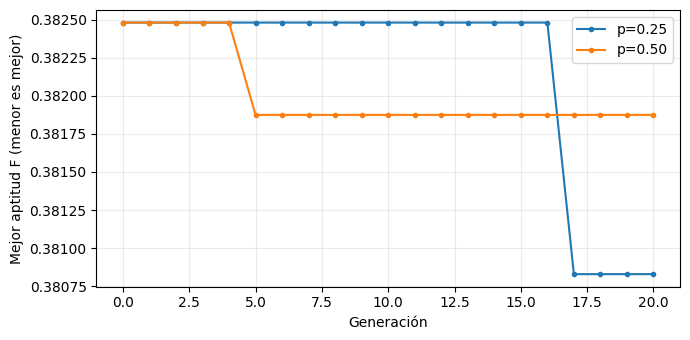

In [25]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel='Generación', ylabel='Mejor aptitud F (menor es mejor)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

El parámetro cambiado fue la probabilidad de mutación: 0.25 en la configuración base y 0.50 en la variante. La población (20), las generaciones (20), la semilla (42) y los demás parámetros se mantuvieron iguales.

Al final, la base obtuvo el mejor $F=0.380829$ y usó $866.847$ m³ de agua potable; la variante obtuvo $F=0.381874$ y usó $869.226$ m³. Como menor $F$ es mejor, la base terminó ligeramente mejor: $0.001045$ menos en $F$ y $2.379$ m³ menos de agua potable. Ambas soluciones son factibles: su exceso es $E=0$ y sus genes respetan los dominios.

En la gráfica, la variante mejora primero: su mejor $F$ baja alrededor de la generación 5 y luego queda en meseta. La base conserva el mejor valor inicial hasta aproximadamente la generación 17, cuando lo mejora y termina con el menor $F$. Una meseta significa que en esas generaciones el algoritmo no encontró una solución que superara a la mejor conservada; no implica que toda la población haya dejado de cambiar.

Esto describe únicamente estas dos ejecuciones con esta semilla y configuración. Muestran que ambas encontraron soluciones factibles y que aquí la base terminó mejor, pero no permiten concluir que una probabilidad de mutación sea generalmente superior ni que el resultado se repita con otras semillas. Para una conclusión general harían falta ejecuciones con varias semillas.

## 11. Comprueba reproducción


In [26]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print('Reproducción y elitismo comprobados.')

Reproducción y elitismo comprobados.


## FINAL - ENTREGABLE 3: ANÁLISIS DEL ALGORITMO Y SUS CONFIGURACIONES

### F0. Versión analizada, correcciones y antecedentes

La versión analizada fue la etapa de Desarrollo: Con los datos, dominios, capacidad y aptitud siendo los de la base, por lo que no cambian. Se usa cruza uniforme 'crossover_uniform', ejecutada con 'run_ga_variant' y 'next_generation_variant'. Tambien selección ('tournament'), mutación ('mutate'), reemplazo con una élite y evaluador ('evaluate').

| Elemento | Qué usamos en Final |
|---|---|
| Código de ambas ejecuciones | Variante (cruza uniforme). No es la base sin modificación. |
| Cambio experimental de Final | Sólo la probabilidad de mutación por gen: pm = 0.25 frente a pm = 0.50 |
| Condiciones comunes | 20 individuos, 20 generaciones, semilla 42 reiniciada en cada ejecución, misma regla de inicialización (`random_individual`), selección por torneo de dos, reemplazo generacional con población constante y una élite |

**Correcciones realizadas antes del Final**

- Corregimos en «Procedencia y entorno» la versión de Python (decía 3.12-3.14; los otros dos archivos .toml y .lock piden >=3.13)
- Marcamos las secciones 9 a 11 como antecedente de la base, para que no se confundan con la evidencia del Final.
- No modificamos ninguna función del algoritmo. como el código no cambió, la ejecución de la variante con pm = 0.25 de Desarrollo sigue siendo válida.

Se conservaron como antecedentes el desarrollo, base frente a variante, ambas con pm = 0.25; y también las secciones 9 a 11, base con pm = 0.25 frente a 0.50, que usa otro código (cruza de un punto) y por eso no se usa como comparación de Final.

### F1. Explicación de una generación de la variante

Elegimos la generación 8 de la ejecución con pm = 0.25: es la transición de la población de la generación 7 a la generación 8, y es donde la mejor aptitud de la variante baja por primera vez respecto del mejor individuo inicial (mejora que la tabla D6 reportó en la generación 8). Así podemos seguir una élite, hijos que no cambian, mutaciones que dañan y una mutación que mejora.

Para que el trazado sea fiel al código, 'traza_generacion' llama a las mismas funciones ('tournament', 'crossover_uniform', 'mutate', 'evaluate') con el mismo generador aleatorio, en el mismo orden que 'next_generation_variant'. Para mostrar que individuos compitieron y qué máscara usó la cruza, copiamos el generador con 'copy.deepcopy' y repetimos solo esa lectura; el generador real avanza igual que en la variante. Al final la celda comprueba que la población obtenida es idéntica a la de 'run_ga_variant'.

In [28]:
import copy

def F(x):
    """Fitness (lower is better) of one chromosome."""
    return evaluate(x)["fitness"]

def poblaciones_variante(mutation_probability, population_size=20, generations=20, seed=42):
    """Re-run run_ga_variant keeping every population and the generator state before each generation."""
    rng = np.random.default_rng(seed)
    pop = [random_individual(rng) for _ in range(population_size)]
    poblaciones, estados = [[x.copy() for x in pop]], [copy.deepcopy(rng)]
    for _ in range(generations):
        pop = next_generation_variant(pop, mutation_probability, rng)
        poblaciones.append([x.copy() for x in pop])
        estados.append(copy.deepcopy(rng))
    return poblaciones, estados

def traza_generacion(population, probability, rng):
    """Same steps as next_generation_variant, but recording what each operator did."""
    idx_elite = min(range(len(population)), key=lambda i: F(population[i]))
    nueva = [population[idx_elite].copy()]           # élite: copia sin tocar
    registros = []
    while len(nueva) < len(population):
        torneos = []
        for _ in range(2):                            # dos torneos -> dos padres
            lector = copy.deepcopy(rng)               # sólo para leer los índices del torneo
            idx = [int(i) for i in lector.choice(len(population), size=2, replace=False)]
            padre = tournament(population, rng)       # función real; avanza el generador real
            torneos.append((idx, padre))
        (ia, pa), (ib, pb) = torneos
        lector = copy.deepcopy(rng)
        mascara = lector.random(len(LIMITS)) < 0.5    # True = gen tomado del padre A
        hijo = crossover_uniform(pa, pb, rng)
        assert np.array_equal(hijo, np.where(mascara, pa, pb))
        mutado = mutate(hijo, probability, rng)
        registros.append(dict(ia=ia, pa=pa, ib=ib, pb=pb, mascara=mascara, hijo=hijo, mutado=mutado))
        nueva.append(mutado)
    return idx_elite, nueva, registros

GEN = 8
poblaciones_025, estados_025 = poblaciones_variante(0.25)
poblacion_previa = poblaciones_025[GEN - 1]
idx_elite, poblacion_nueva, registros = traza_generacion(
    poblacion_previa, 0.25, copy.deepcopy(estados_025[GEN - 1]))

# La traza reproduce exactamente la variante
assert all(np.array_equal(a, b) for a, b in zip(poblacion_nueva, poblaciones_025[GEN]))
assert all(np.array_equal(a, b) for a, b in zip(next_generation_variant(
    poblacion_previa, 0.25, copy.deepcopy(estados_025[GEN - 1])), poblacion_nueva))
print("La traza coincide con next_generation_variant y con run_ga_variant.\n")

def fila(i, x):
    m = evaluate(x)
    return f"{i:>3}  {str(tuple(int(k) for k in x)):<14}{m['treated']:>10.3f}{m['excess']:>9.3f}{m['fitness']:>10.6f}  {'sí' if m['feasible'] else 'NO'}"

print(f"POBLACIÓN DE LA GENERACIÓN {GEN - 1} (entrada)")
print(f"{'i':>3}  {'genes':<14}{'T (m³)':>10}{'E (m³)':>9}{'F':>10}  factible")
for i, x in enumerate(poblacion_previa):
    print(fila(i, x) + ("   <- élite (menor F)" if i == idx_elite else ""))
print()
print(f"Élite: individuo {idx_elite} con genes {tuple(int(k) for k in poblacion_previa[idx_elite])} y F = {F(poblacion_previa[idx_elite]):.6f}")
print(f"Mejor F de la población previa: {min(F(x) for x in poblacion_previa):.6f}")
print(f"Individuos infactibles en la población previa: {sum(not evaluate(x)['feasible'] for x in poblacion_previa)} de {len(poblacion_previa)}")

La traza coincide con next_generation_variant y con run_ga_variant.

POBLACIÓN DE LA GENERACIÓN 7 (entrada)
  i  genes             T (m³)   E (m³)         F  factible
  0  (6, 6, 5, 7)    1405.605    0.000  0.382480  sí   <- élite (menor F)
  1  (6, 4, 5, 8)    1381.505    0.000  0.393068  sí
  2  (6, 5, 4, 7)    1330.984    0.000  0.415263  sí
  3  (6, 6, 5, 7)    1405.605    0.000  0.382480  sí
  4  (6, 5, 2, 8)    1342.442    0.000  0.410229  sí
  5  (6, 4, 1, 8)    1267.821    0.000  0.443012  sí
  6  (4, 6, 6, 8)    1332.926    0.000  0.414410  sí
  7  (4, 6, 3, 7)    1179.363    0.000  0.481874  sí
  8  (6, 4, 1, 8)    1267.821    0.000  0.443012  sí
  9  (6, 6, 4, 7)    1377.184    0.000  0.394966  sí
 10  (4, 6, 5, 7)    1236.205    0.000  0.456902  sí
 11  (5, 6, 6, 7)    1349.326    0.000  0.407205  sí
 12  (6, 7, 5, 8)    1520.105  110.105  1.078089  NO
 13  (6, 5, 5, 6)    1291.105    0.000  0.432783  sí
 14  (6, 5, 5, 8)    1427.705   17.705  1.012557  NO
 15  (5, 7, 1, 7)

In [29]:
print(f"HIJOS DE LA GENERACIÓN {GEN}: padres (índice, F) -> máscara -> hijo tras cruza -> hijo tras mutación")
print("máscara: 1 = el gen viene del padre A, 0 = viene del padre B\n")
for j, r in enumerate(registros, start=1):
    g = lambda x: tuple(int(k) for k in x)
    mutaron = [f"k{n+1}" for n in range(4) if r["hijo"][n] != r["mutado"][n]]
    print(f"Hijo {j:>2} | torneo 1: {r['ia']} F={[round(F(poblacion_previa[i]), 4) for i in r['ia']]} gana {g(r['pa'])}"
          f" | torneo 2: {r['ib']} F={[round(F(poblacion_previa[i]), 4) for i in r['ib']]} gana {g(r['pb'])}")
    print(f"        máscara {''.join(str(int(b)) for b in r['mascara'])} -> cruza {g(r['hijo'])} F={F(r['hijo']):.6f}"
          f" -> mutación {mutaron if mutaron else 'ninguna'} -> {g(r['mutado'])} F={F(r['mutado']):.6f}"
          f"{'' if evaluate(r['mutado'])['feasible'] else '  (INFACTIBLE)'}")

print()
n_mut = sum(not np.array_equal(r["hijo"], r["mutado"]) for r in registros)
n_infact = sum(not evaluate(r["mutado"])["feasible"] for r in registros)
print(f"Hijos (19) cuya mutación cambió al menos un gen: {n_mut}")
print(f"Hijos infactibles tras la mutación: {n_infact}")
mejoran = sum(F(r["mutado"]) < F(r["hijo"]) - 1e-12 for r in registros)
empeoran = sum(F(r["mutado"]) > F(r["hijo"]) + 1e-12 for r in registros)
print(f"Mutaciones que bajaron F (mejoraron): {mejoran}; que subieron F (empeoraron): {empeoran}")
print(f"Mejor F de la población nueva: {min(F(x) for x in poblacion_nueva):.6f} "
      f"(élite previa: {F(poblacion_previa[idx_elite]):.6f})")

# Hijo 3: el recorrido que explicamos en el texto
r3 = registros[2]
assert tuple(int(k) for k in r3["mutado"]) == (6, 4, 6, 8)
assert F(r3["mutado"]) < F(poblacion_previa[idx_elite])

HIJOS DE LA GENERACIÓN 8: padres (índice, F) -> máscara -> hijo tras cruza -> hijo tras mutación
máscara: 1 = el gen viene del padre A, 0 = viene del padre B

Hijo  1 | torneo 1: [19, 9] F=[0.4474, 0.395] gana (6, 6, 4, 7) | torneo 2: [8, 9] F=[0.443, 0.395] gana (6, 6, 4, 7)
        máscara 0011 -> cruza (6, 6, 4, 7) F=0.394966 -> mutación ninguna -> (6, 6, 4, 7) F=0.394966
Hijo  2 | torneo 1: [10, 2] F=[0.4569, 0.4153] gana (6, 5, 4, 7) | torneo 2: [6, 3] F=[0.4144, 0.3825] gana (6, 6, 5, 7)
        máscara 1001 -> cruza (6, 6, 5, 7) F=0.382480 -> mutación ['k3', 'k4'] -> (6, 6, 4, 8) F=1.025166  (INFACTIBLE)
Hijo  3 | torneo 1: [1, 12] F=[0.3931, 1.0781] gana (6, 4, 5, 8) | torneo 2: [8, 14] F=[0.443, 1.0126] gana (6, 4, 1, 8)
        máscara 0110 -> cruza (6, 4, 5, 8) F=0.393068 -> mutación ['k3'] -> (6, 4, 6, 8) F=0.380582
Hijo  4 | torneo 1: [16, 18] F=[0.44, 1.005] gana (5, 5, 5, 7) | torneo 2: [19, 4] F=[0.4474, 0.4102] gana (6, 5, 2, 8)
        máscara 0111 -> cruza (6, 5, 5, 

#### Lectura del trazado

Con la generación 8 y pm = 0.25

Sobre la entrada y dirección de la aptitud, la población de la generación 7 tiene 20 individuos, 3 de ellos infactibles (los individuos 12, 14 y 18, con $E>0$ y por tanto $F>1$). Menor $F$ es mejor: un plan factible tiene $F=P/Q\le1$ y uno que rebasa la capacidad tiene $F=1+E/C>1$, de modo que cualquier plan factible gana a cualquiera infactible. La mejor $F$ de la entrada es $0.382480$ y corresponde al individuo 0, $k=(6,6,5,7)$ ($T=1405.605$ m³, margen de 4.395 m³).

Con respecto a la élite y reemplazo ('next_generation_variant'), la primera línea de la función, 'elite = min(population, key=...).copy()', selecciona el individuo de menor $F$ (el 0; el 3 es idéntico pero 'min' devuelve el primero) y guarda una copia independiente en la posición 0 de 'replacement'. Esa copia no pasa por cruza ni mutación, así que la nueva población conserva $k=(6,6,5,7)$ con $F=0.382480$ y la mejor aptitud no puede empeorar (en el código, el 'while' sólo agrega 19 hijos más). El resto de las posiciones se llena con los 19 hijos: el reemplazo es generacional, los padres no pasan a la población siguiente salvo por esa copia de la élite y el tamaño sigue siendo 20.

Función de cada operador con candidatos concretos

| Operador (función) | Qué cambia en la población | Ejemplo de esta generación |
|---|---|---|
| Selección (`tournament`) | No cambia genes; decide quién se reproduce: de dos individuos al azar gana el de menor $F$ | Hijo 5, torneo 1: el individuo 14 $(6,5,5,8)$ tiene $F=1.0126$ (infactible) y el 16 $(5,5,5,7)$ tiene $F=0.4400$; gana el 16 porque su $F$ es menor |
| Cruza uniforme (`crossover_uniform`, el operador modificado) | Crea un hijo que toma cada gen de uno de los dos padres según una moneda; no inventa valores | Hijo 3: padres $A=(6,4,5,8)$ y $B=(6,4,1,8)$, máscara `0110` (1 = gen del padre A): $k_1$ de B, $k_2$ de A, $k_3$ de A y $k_4$ de B, hijo $(6,4,5,8)$ |
| Mutación (`mutate`) | Con probabilidad pm por gen sube o baja un nivel válido; es la única fuente de valores nuevos | Hijo 3: sólo se elige $k_3$ y pasa de 5 a 6 |
| Reemplazo (`next_generation_variant`) | La población nueva = élite + 19 hijos | Posición 0: élite $(6,6,5,7)$; posiciones 1 a 19: hijos |

**Recorrido completo del hijo 3 (el que mejora).**

1. *Selección.* Torneo 1 entre los individuos 1 $(6,4,5,8)$ con $F=0.393068$ y 12 $(6,7,5,8)$ con $F=1.078089$ (infactible): gana el 1. Torneo 2 entre el 8 $(6,4,1,8)$ con $F=0.443012$ y el 14 con $F=1.012557$ (infactible): gana el 8. Las dos victorias son por menor $F$.
2. *Cruza uniforme.* La máscara `0110` produce $(6,4,5,8)$, con $F=0.393068$. Aquí los padres sólo difieren en $k_3$ y la moneda tomó el $k_3$ del padre A, así que el hijo salió igual que A: la cruza no mejoró nada, sólo recombinó.
3. *Mutación.* Sólo $k_3$ fue elegido; sus vecinos válidos eran 4 y 6 y salió 6. Eso suma $0.1\times284.21=28.421$ m³ de agua tratada: $T$ pasa de 1381.505 a 1409.926 m³, todavía $\le1410$ (margen 0.074 m³). El hijo final $(6,4,6,8)$ tiene $E=0$ y $F=0.380582$.
4. *Reemplazo.* Ocupa la posición 3 de la población nueva y su $F=0.380582$ es menor que la de la élite previa ($0.382480$). Desde aquí la élite de la siguiente generación será este individuo.

**Dos casos que muestran que la mutación puede dañar.** En el hijo 2 la cruza (máscara `1001`) da $(6,6,5,7)$ con $F=0.382480$, pero la mutación cambia $k_3$ de 5 a 4 ($-28.421$ m³) y $k_4$ de 7 a 8 ($+68.300$ m³): $T=1445.484$ m³, $E=35.484$ m³ y $F=1+35.484/1410=1.025166$. Pasó de factible a infactible y queda con peor aptitud; el reemplazo lo incorpora de todos modos, pero será descartado con facilidad en los torneos de la generación siguiente. En el hijo 7 la mutación de $k_1$ (6 a 7) lleva $(6,6,5,7)$ a $F=1.056954$. En total, de los 19 hijos, 11 tuvieron al menos un gen mutado; 4 de esas mutaciones bajaron $F$ (mejoraron: hijos 3, 8, 9 y 19) y 7 la subieron (hijos 2, 5, 7, 11, 14, 15 y 18).

**Un caso donde casi nada cambia.** En el hijo 1 los dos torneos los gana el mismo individuo, el 9 $(6,6,4,7)$. Con padres iguales la cruza uniforme devuelve una copia (lo comprobamos en las pruebas de D3 con `crossover_uniform(pa, pa)`) y la mutación no eligió ningún gen, de modo que el hijo es un clon del padre.

**Resultado de la generación.** La población nueva tiene 2 individuos infactibles (hijos 2 y 7), los 3 infactibles previos desaparecieron (ninguno ganó un torneo) y su mejor $F$ es $0.380582$, frente a $0.382480$. La mejora vino de una mutación afortunada sobre un hijo que era copia de un padre; la élite garantizó que no se perdiera lo que ya se tenía mientras los operadores exploraban.

### F2. Comparación pm = 0.25 frente a pm = 0.50 (misma versión: variante)

Usamos **el mismo código** (`run_ga_variant`, cruza uniforme) y los mismos operadores. Lo único que cambia es `mutation_probability`. Cada ejecución crea su propio generador con la semilla 42 dentro de `run_ga_variant`, de modo que ninguna arrastra el estado aleatorio de la otra. No usamos la base ni mezclamos sus resultados.

| Condición | pm = 0.25 | pm = 0.50 |
|---|---|---|
| Código | `run_ga_variant` | `run_ga_variant` |
| Población / generaciones | 20 / 20 | 20 / 20 |
| Semilla y población inicial | 42, `random_individual` | 42, `random_individual` |
| Selección, cruza, reemplazo, élite | Torneo de dos, cruza uniforme, generacional con una élite | Igual |
| Problema y evaluador | Mismos datos, dominios, objetivo, capacidad y `evaluate` | Igual |
| **Probabilidad de mutación por gen** | **0.25** | **0.50** |

In [30]:
CONFIG_FINAL = dict(population_size=20, generations=20, seed=42)
PM_A, PM_B = 0.25, 0.50

# Cada llamada crea su propio generador con la semilla 42: no hay estado compartido.
final_025 = run_ga_variant(mutation_probability=PM_A, **CONFIG_FINAL)
final_050 = run_ga_variant(mutation_probability=PM_B, **CONFIG_FINAL)

# El código no cambió desde Desarrollo: la ejecución con 0.25 debe coincidir con variant_dev
np.testing.assert_array_equal(final_025["genes"], variant_dev["genes"])
np.testing.assert_array_equal(final_025["history"], variant_dev["history"])
print("La ejecución con pm = 0.25 coincide con la variante de Desarrollo (variant_dev).")

# Misma población inicial en ambas ejecuciones
rng_i = np.random.default_rng(CONFIG_FINAL["seed"])
pob_inicial = [random_individual(rng_i) for _ in range(CONFIG_FINAL["population_size"])]
assert final_025["history"][0] == final_050["history"][0] == min(F(x) for x in pob_inicial)
mejor_inicial_final = min(pob_inicial, key=F)
print(f"Mejor individuo inicial (igual en ambas): {tuple(int(k) for k in mejor_inicial_final)}  F = {F(mejor_inicial_final):.6f}")

# Reproducción: repetir cada ejecución desde el inicio da los mismos genes e historia
for pm, res in [(PM_A, final_025), (PM_B, final_050)]:
    rep = run_ga_variant(mutation_probability=pm, **CONFIG_FINAL)
    np.testing.assert_array_equal(res["genes"], rep["genes"])
    np.testing.assert_array_equal(res["history"], rep["history"])
    assert np.all(np.diff(res["history"]) <= 1e-12)          # la élite impide que la mejor F empeore
    audit = audit_run(next_generation_variant, mutation_probability=pm, **CONFIG_FINAL)
    np.testing.assert_array_equal(audit["history"], res["history"])
    print(f"pm = {pm:.2f}: reproducible, mejor F sin empeorar, población constante y élite conservada.")

# Configuración, entorno y mejor candidato por generación (rastreado con las mismas funciones)
print()
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| Matplotlib:", matplotlib.__version__)
print("Configuración común:", CONFIG_FINAL, "| cambio experimental: mutation_probability =", (PM_A, PM_B))

def mejores_por_generacion(pm):
    pobs, _ = poblaciones_variante(pm, **CONFIG_FINAL)
    hist = np.array([min(F(x) for x in p) for p in pobs])
    return [min(p, key=F).copy() for p in pobs], hist

mejores_025, hist_025 = mejores_por_generacion(PM_A)
mejores_050, hist_050 = mejores_por_generacion(PM_B)
np.testing.assert_array_equal(hist_025, final_025["history"])
np.testing.assert_array_equal(hist_050, final_050["history"])

print("\nGeneraciones en las que cambia la mejor aptitud:")
for pm, mejores, hist in [(PM_A, mejores_025, hist_025), (PM_B, mejores_050, hist_050)]:
    print(f"  pm = {pm:.2f}")
    for g in range(len(hist)):
        if g == 0 or hist[g] < hist[g - 1] - 1e-12:
            print(f"    generación {g:>2}: {tuple(int(k) for k in mejores[g])}  F = {hist[g]:.6f}  T = {evaluate(mejores[g])['treated']:.3f} m³")

La ejecución con pm = 0.25 coincide con la variante de Desarrollo (variant_dev).
Mejor individuo inicial (igual en ambas): (6, 6, 5, 7)  F = 0.382480
pm = 0.25: reproducible, mejor F sin empeorar, población constante y élite conservada.
pm = 0.50: reproducible, mejor F sin empeorar, población constante y élite conservada.

Python: 3.13.16 | NumPy: 2.1.3 | Matplotlib: 3.10.0
Configuración común: {'population_size': 20, 'generations': 20, 'seed': 42} | cambio experimental: mutation_probability = (0.25, 0.5)

Generaciones en las que cambia la mejor aptitud:
  pm = 0.25
    generación  0: (6, 6, 5, 7)  F = 0.382480  T = 1405.605 m³
    generación  8: (6, 4, 6, 8)  F = 0.380582  T = 1409.926 m³
  pm = 0.50
    generación  0: (6, 6, 5, 7)  F = 0.382480  T = 1405.605 m³
    generación 15: (6, 7, 1, 8)  F = 0.382122  T = 1406.421 m³
    generación 16: (6, 4, 6, 8)  F = 0.380582  T = 1409.926 m³


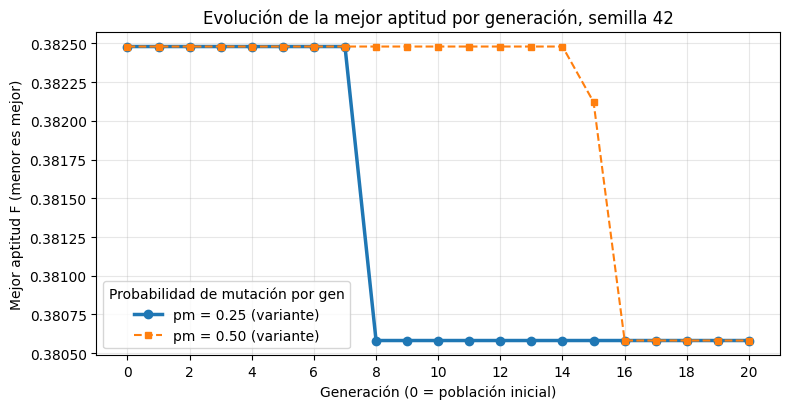

In [31]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.2))
gens = np.arange(len(final_025["history"]))
ax.plot(gens, final_025["history"], color="tab:blue", marker="o", markersize=6, linewidth=2.5,
        label="pm = 0.25 (variante)")
ax.plot(gens, final_050["history"], color="tab:orange", marker="s", markersize=4, linewidth=1.5,
        linestyle="--", label="pm = 0.50 (variante)")
ax.set_xlabel("Generación (0 = población inicial)")
ax.set_ylabel("Mejor aptitud F (menor es mejor)")
ax.set_title("Evolución de la mejor aptitud por generación, semilla 42")
ax.set_xticks(range(0, 21, 2))
ax.grid(alpha=0.3)
ax.legend(title="Probabilidad de mutación por gen")
fig.tight_layout()
plt.show()

In [32]:
def tabla_configuracion(pm, res):
    g = res["genes"]
    m = evaluate(g)
    dominio = bool(np.all((g >= 0) & (g <= LIMITS)))
    # comprobación independiente con decimales exactos
    T_ex = sum(d * int(k) / 10 for d, k in zip(D_EXACT, g))
    assert abs(float(T_ex) - m["treated"]) < 1e-9 and abs(float(sum(D_EXACT) - T_ex) - m["potable"]) < 1e-9
    h = res["history"]
    primera = int(np.where(h <= h[-1] + 1e-12)[0][0])
    return dict(pm=pm, genes=tuple(int(k) for k in g), T=m["treated"], P=m["potable"], F=m["fitness"],
                E=m["excess"], dominio=dominio, capacidad=m["feasible"], margen=CAPACITY - m["treated"],
                primera=primera)

filas_final = [tabla_configuracion(PM_A, final_025), tabla_configuracion(PM_B, final_050)]
print(f"{'':<34}{'pm = 0.25':>16}{'pm = 0.50':>16}")
etiquetas = [
    ("Cromosoma final (k1,k2,k3,k4)", lambda r: str(r["genes"])),
    ("Agua tratada T (m³)", lambda r: f"{r['T']:.3f}"),
    ("Agua potable P (m³)", lambda r: f"{r['P']:.3f}"),
    ("Aptitud F", lambda r: f"{r['F']:.6f}"),
    ("Exceso E (m³)", lambda r: f"{r['E']:.3f}"),
    ("Margen C - T (m³)", lambda r: f"{r['margen']:.3f}"),
    ("Genes dentro de dominio", lambda r: "sí" if r["dominio"] else "NO"),
    ("Capacidad (E <= 1e-8 m³)", lambda r: "cumple" if r["capacidad"] else "NO cumple"),
    ("Primera gen. con la mejor F final", lambda r: str(r["primera"])),
]
for nombre, f in etiquetas:
    print(f"{nombre:<34}{f(filas_final[0]):>16}{f(filas_final[1]):>16}")

a, b = filas_final
print()
print("Mismo cromosoma final:", a["genes"] == b["genes"])
print(f"Diferencia de P entre configuraciones: {b['P'] - a['P']:.3e} m³ (ambas factibles: {a['capacidad'] and b['capacidad']})")
print(f"Gap de P frente a la mejor combinación factible de las 5103 {mejor_k}: {a['P'] - mejor_m['potable']:.3f} m³")

                                         pm = 0.25       pm = 0.50
Cromosoma final (k1,k2,k3,k4)         (6, 4, 6, 8)    (6, 4, 6, 8)
Agua tratada T (m³)                       1409.926        1409.926
Agua potable P (m³)                        866.284         866.284
Aptitud F                                 0.380582        0.380582
Exceso E (m³)                                0.000           0.000
Margen C - T (m³)                            0.074           0.074
Genes dentro de dominio                         sí              sí
Capacidad (E <= 1e-8 m³)                    cumple          cumple
Primera gen. con la mejor F final                8              16

Mismo cromosoma final: True
Diferencia de P entre configuraciones: 0.000e+00 m³ (ambas factibles: True)
Gap de P frente a la mejor combinación factible de las 5103 (8, 6, 4, 5): 0.058 m³


#### Resultados y lectura de la gráfica

| Medida | pm = 0.25 | pm = 0.50 |
|---|---|---|
| Cromosoma final $(k_1,k_2,k_3,k_4)$ | $(6,4,6,8)$ | $(6,4,6,8)$ |
| Agua tratada $T$ / potable $P$ (m³) | $1409.926$ / $866.284$ | $1409.926$ / $866.284$ |
| Aptitud $F$ / exceso $E$ (m³) | $0.380582$ / $0$ | $0.380582$ / $0$ |
| Dominios y capacidad | Genes enteros dentro de dominio; $T\le C$ con margen de 0.074 m³: factible | Igual: factible, margen de 0.074 m³ |
| Primera generación con la mejor $F$ final | 8 | 16 |

**Coincidencias.** Ambas ejecuciones parten de la misma población inicial (semilla 42), cuyo mejor individuo es $(6,6,5,7)$ con $F=0.382480$, así que las dos curvas coinciden en la generación 0. Ambas terminan en el **mismo cromosoma** $(6,4,6,8)$, con el mismo $T$, $P$, $F$ y $E=0$: las dos son factibles y el agua potable es igual (diferencia de 0 m³ entre candidatos factibles). Las curvas también se superponen en las generaciones 16 a 20.

**Diferencias y mesetas.** Con pm = 0.25 la mejor aptitud permanece en $0.382480$ de la generación 0 a la 7 (meseta inicial), baja a $0.380582$ en la generación 8 (el hijo 3 que trazamos en F1) y se queda ahí hasta la 20. Con pm = 0.50 la meseta inicial es más larga (generaciones 0 a 14), después hay un paso intermedio en la generación 15 ($F=0.382122$ con $(6,7,1,8)$, $T=1406.421$ m³) y en la 16 llega al mismo cromosoma final. En la gráfica la línea de pm = 0.25 queda por debajo de la de pm = 0.50 entre las generaciones 8 y 15, con una separación de $0.001898$ en $F$ en las generaciones 8 a 14 y de $0.001540$ en la 15. Una meseta significa que el mejor valor conservado no fue superado en esas generaciones; no quiere decir que la población dejara de cambiar (en F1 vimos que cada generación reemplaza 19 de los 20 individuos).

**Relación con los candidatos finales.** Como el candidato final es el mismo, el resultado final no distingue las configuraciones. Lo único que las separa es cuándo lo alcanzan: con pm = 0.25 en la generación 8 y con pm = 0.50 en la 16, es decir, ocho generaciones después. En esta ejecución pm = 0.50 no mejoró ni empeoró el resultado final; empató y tardó más. Además, ninguna llegó a la mejor combinación factible de las 5103 posibles, $(8,6,4,5)$ con $P=866.226$ m³, que queda 0.058 m³ por debajo (referencia calculada en Desarrollo, que no forma parte del algoritmo).

**Límites de la comparación.**

- Es **una sola semilla** (42). No sabemos si el empate en el resultado final o la diferencia de 8 generaciones se repetirían con otras semillas; con otra podría ocurrir lo contrario. No afirmamos que una probabilidad sea mejor que la otra en general.
- Cambiar pm también cambia cuántos números aleatorios consume `mutate` en cada generación (uno por gen y uno más cuando el gen es elegido), así que las dos ejecuciones siguen secuencias aleatorias distintas desde la generación 1. La diferencia observada mezcla el efecto de pm con la suerte de esa secuencia, y no podemos separarlos con una semilla.
- No medimos cuántos hijos infactibles produce cada pm ni la diversidad de la población, así que no podemos atribuir la demora de pm = 0.50 a un mecanismo concreto; sólo describimos lo observado.
- Sólo comparamos agua potable entre candidatos factibles. Un $P$ menor con $E>0$ no es una mejora (por ejemplo, el cromosoma máximo $(8,8,6,8)$ tiene $P=512.084$ m³ pero rebasa la capacidad en 354.126 m³).
- Esta comparación (variante, 0.25 frente a 0.50) es distinta de la de las secciones 9 a 11 (base, otra cruza) y de la de Desarrollo (base frente a variante con pm = 0.25); no las mezclamos ni las usamos para sustituirse.

### F3. Interpretación física de los resultados de Final

La siguiente celda traduce los cromosomas finales de **las dos configuraciones** a fracciones, volúmenes tratados y potables por edificio y uso de la capacidad. También incluye, como referencia, el mejor individuo inicial (compartido por ambas ejecuciones) y la mejor combinación factible de las 5103 calculada en Desarrollo. Esa referencia sólo dimensiona la mejora posible y no forma parte del algoritmo.

In [33]:
def detalle_fisico(titulo, genes):
    genes = np.asarray(genes, dtype=int)
    m = evaluate(genes)
    T_i = DEMAND * genes / 10
    P_i = DEMAND - T_i
    print(titulo, tuple(int(k) for k in genes))
    print(f"  {'edificio':<12}{'D_i (m³)':>10}{'k_i':>5}{'x_i':>6}{'T_i (m³)':>11}{'P_i (m³)':>11}{'% de T':>9}")
    for n, d, k, t, p in zip(BUILDINGS, DEMAND, genes, T_i, P_i):
        print(f"  {n:<12}{d:>10.2f}{int(k):>5}{k / 10:>6.1f}{t:>11.3f}{p:>11.3f}{100 * t / m['treated']:>8.1f}%")
    assert np.isclose(T_i.sum(), m["treated"]) and np.isclose(P_i.sum(), m["potable"])
    print(f"  {'Total':<12}{DEMAND.sum():>10.2f}{'':>11}{m['treated']:>11.3f}{m['potable']:>11.3f}")
    print(f"  Uso de capacidad T/C = {100 * m['treated'] / CAPACITY:.3f} %  margen = {CAPACITY - m['treated']:.3f} m³  "
          f"E = {m['excess']:.3f} m³  reúso global T/Q = {100 * m['treated'] / DEMAND.sum():.1f} %\n")

detalle_fisico("pm = 0.25, final:", final_025["genes"])
detalle_fisico("pm = 0.50, final:", final_050["genes"])
detalle_fisico("Referencia: mejor individuo inicial (ambas ejecuciones):", mejor_inicial_final)
detalle_fisico("Referencia: mejor combinación factible de las 5103:", mejor_k)

# Mejor candidato de pm = 0.50 justo antes de alcanzar su cromosoma final
g_prev = int(np.where(hist_050 <= hist_050[-1] + 1e-12)[0][0]) - 1
detalle_fisico(f"pm = 0.50, mejor candidato en la generación {g_prev} (antes de llegar al final):", mejores_050[g_prev])

pm = 0.25, final: (6, 4, 6, 8)
  edificio      D_i (m³)  k_i   x_i   T_i (m³)   P_i (m³)   % de T
  AULAS 1         847.00    6   0.6    508.200    338.800    36.0%
  BIBLIOTECA      462.00    4   0.4    184.800    277.200    13.1%
  CEDETEC         284.21    6   0.6    170.526    113.684    12.1%
  AULAS 2         683.00    8   0.8    546.400    136.600    38.8%
  Total          2276.21              1409.926    866.284
  Uso de capacidad T/C = 99.995 %  margen = 0.074 m³  E = 0.000 m³  reúso global T/Q = 61.9 %

pm = 0.50, final: (6, 4, 6, 8)
  edificio      D_i (m³)  k_i   x_i   T_i (m³)   P_i (m³)   % de T
  AULAS 1         847.00    6   0.6    508.200    338.800    36.0%
  BIBLIOTECA      462.00    4   0.4    184.800    277.200    13.1%
  CEDETEC         284.21    6   0.6    170.526    113.684    12.1%
  AULAS 2         683.00    8   0.8    546.400    136.600    38.8%
  Total          2276.21              1409.926    866.284
  Uso de capacidad T/C = 99.995 %  margen = 0.074 m³  E =

#### Interpretación por edificio, volúmenes y capacidad

**Asignación final (la misma en pm = 0.25 y pm = 0.50): $k=(6,4,6,8)$.**

| Edificio | $D_i$ (m³) | Fracción tratada $x_i$ | $T_i$ (m³) | $P_i$ (m³) |
|---|---|---|---|---|
| Aulas 1 | 847.00 | 0.6 (60 %) | 508.200 | 338.800 |
| Biblioteca | 462.00 | 0.4 (40 %) | 184.800 | 277.200 |
| Cedetec | 284.21 | 0.6 (60 %, su máximo didáctico) | 170.526 | 113.684 |
| Aulas 2 | 683.00 | 0.8 (80 %, su máximo didáctico) | 546.400 | 136.600 |
| Total | 2276.21 | 61.9 % global | 1409.926 | 866.284 |

- **Qué significa cada fracción.** $x_i=k_i/10$ es la parte de la demanda mensual de ese edificio que se cubre con agua tratada; el resto sale de agua potable ($T_i+P_i=D_i$ en cada fila). Aulas 2 y Cedetec llegan al tope de su dominio; Aulas 1 y Biblioteca quedan por debajo de su tope (80 %).
- **Capacidad.** El agua tratada total es $T=1409.926$ m³, el $99.995\,\%$ de los 1410 m³ de capacidad didáctica: $E=0$ y queda un margen de apenas 0.074 m³. La capacidad es la restricción que realmente limita el plan, no los dominios. Con ese margen no cabe ningún aumento de un nivel en los edificios que todavía pueden subir: Aulas 1 agregaría 84.700 m³ y Biblioteca 46.200 m³, ambos mucho mayores que 0.074 m³ (Cedetec y Aulas 2 ya están en su máximo). Por eso, desde ese candidato ningún aumento de un solo nivel es factible; sólo un cambio compuesto (bajar un gen y subir otro) podría mejorarlo, como lo hace la mejor combinación de las 5103.
- **Potable y tratada por edificio.** Aulas 1 y Aulas 2 reciben juntas el $74.8\,\%$ del agua tratada ($36.0\,\%+38.8\,\%$), sobre todo porque tienen las demandas más grandes. Biblioteca, con sólo 40 % de reúso, sigue aportando 277.200 m³ de agua potable, la segunda cifra más alta después de Aulas 1.
- **Coincidencias y diferencias físicas entre las dos configuraciones.** En el resultado final no hay diferencias físicas: mismas fracciones, mismos volúmenes por edificio, mismo uso de capacidad y mismo margen. Lo que cambia es la trayectoria. El mejor candidato de pm = 0.50 en la generación 15 fue $(6,7,1,8)$: Biblioteca al 70 % (323.400 m³ tratados) y Cedetec al 10 % (28.421 m³), con $T=1406.421$ m³, margen de 3.579 m³ y $P=869.789$ m³. Frente a la asignación final, mueve unos 138.600 m³ de tratamiento hacia Biblioteca y quita 142.105 m³ a Cedetec, con un efecto neto de sólo $-3.505$ m³ en $T$. Lo mismo vale para el mejor individuo inicial $(6,6,5,7)$ ($T=1405.605$ m³, $P=870.605$ m³) y para la mejor combinación de las 5103, $(8,6,4,5)$ ($T=1409.984$ m³, $P=866.226$ m³), que reparte el reúso de forma muy distinta (Aulas 1 al 80 %, Aulas 2 al 50 %) y aun así queda a 0.058 m³ de nuestro resultado.
- **Lectura de esas coincidencias.** Como $F$ sólo depende del total $T$, el modelo es indiferente a cómo se reparta el agua tratada entre edificios: asignaciones físicamente muy distintas dan casi el mismo $P$. Por eso un único cromosoma final no es "la" solución, y el modelo no permite preferir entre repartos con el mismo total.

**Alcance y supuestos.**

- **Datos observados:** las demandas $D_i$ de marzo de 2025 (847.00, 462.00, 284.21 y 683.00 m³). **Supuestos didácticos:** la capacidad de 1410 m³, los máximos de reúso por edificio (80 %, 80 %, 60 %, 80 %) y la tolerancia de $10^{-8}$ m³. Que el algoritmo use el 99.995 % de la capacidad es un resultado dentro de esos supuestos, no un hecho de la planta.
- **Alcance:** un solo mes y cuatro edificios; no representa otros meses ni un año completo. Con una sola semilla, el resultado es un caso de un proceso aleatorio.
- **Lo que el modelo no incluye:** costos, distancias, calidad del agua, picos de demanda, variación diaria ni la capacidad real de la planta. Un margen de 0.074 m³ sobre 1410 m³ es lo bastante estrecho como para que un cambio mínimo en la demanda o en la capacidad lo invierta, así que no afirmamos que este plan sea robusto ni ejecutable.
- **Conclusión:** el resultado es un ejercicio didáctico mensual que muestra cómo el algoritmo reparte un recurso limitado bajo una capacidad supuesta. No constituye una recomendación hidráulica ni sanitaria validada.

## Procedencia y entorno

Usamos `assets/kit/datos/consumo_agua_2023_2026.csv` y `assets/kit/parametros_reto.csv` del repositorio técnico MA2015-Planta-Fisica, filtrados a marzo de 2025. La metadata conserva los cuatro registros y los hashes de las fuentes completas. El caso mensual y el código son autónomos.

Con Python 3.12–3.14 y los archivos proporcionados, prepara el entorno con `uv sync --locked` y abre Jupyter con `uv run jupyter lab`. NumPy realiza los cálculos y Matplotlib dibuja la gráfica. Los resultados representan este modelo didáctico, no una recomendación hidráulica o sanitaria validada.